In [1]:
# 01. Business Problem
USE_CASE = "21 - Material Master Data Quality Scoring (Detect Incomplete or Incorrect Material Records)"
ML_PARADIGM = "Unsupervised Anomaly Detection (5 Models Ranked -> 1 Champion Model Selected)"
SERVER = "192.168.1.44:5432 / JKC_Input"
SCHEMAS = ["HANA_P2", "HANA_P3"]
CONTAMINATION_RATE = 0.05

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Server & Schemas: {SERVER} -> {SCHEMAS} (ALL Records, No Limit)")
print(f"Expected Anomaly Rate: {CONTAMINATION_RATE * 100:.0f}%")


Business Problem: 21 - Material Master Data Quality Scoring (Detect Incomplete or Incorrect Material Records)
ML Approach:      Unsupervised Anomaly Detection (5 Models Ranked -> 1 Champion Model Selected)
Server & Schemas: 192.168.1.44:5432 / JKC_Input -> ['HANA_P2', 'HANA_P3'] (ALL Records, No Limit)
Expected Anomaly Rate: 5%


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMAS = ["HANA_P2", "HANA_P3"]
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: {DB_SCHEMAS})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: ['HANA_P2', 'HANA_P3'])


In [4]:
# 04. Extract ALL Data from SAP Material Master Tables (MARA, MAKT, MARC, MBEW, MARM, EINA, T134T, T001W, T001) across HANA_P2 & HANA_P3
from src.db_connector import extract_material_master_data

df_raw = extract_material_master_data(limit=None, schemas=DB_SCHEMAS)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


[INFO] Extracting all SAP Material Master records from schema: HANA_P2 (limit=ALL)...
[SUCCESS] Extracted 218,125 records from HANA_P2.
[INFO] Extracting all SAP Material Master records from schema: HANA_P3 (limit=ALL)...
[SUCCESS] Extracted 489,094 records from HANA_P3.
[SUCCESS] Combined extraction complete: Total 707,219 Material Master records across schemas ['HANA_P2', 'HANA_P3'].
Extracted records: 707,219 rows, 67 columns


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['source_schema', 'material_id', 'material_desc', 'material_type', 'material_group', 'plant', 'plant_name', 'valuation_class', 'moving_avg_price', 'standard_price']].head()


Dataset Shape: (707219, 67)


In [6]:
# 06. Data Understanding / EDA
df_raw[['gross_weight', 'net_weight', 'moving_avg_price', 'standard_price', 'total_valuated_stock', 'total_stock_value']].describe().T


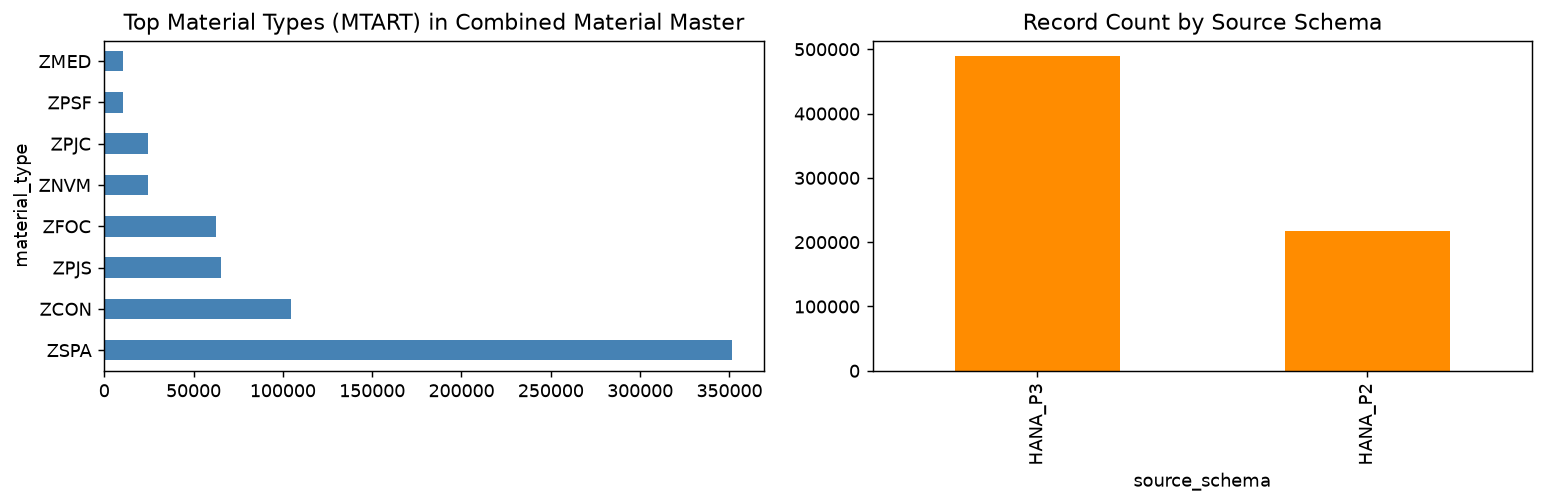

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['material_type'].value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Material Types (MTART) in Combined Material Master')

plt.subplot(1, 2, 2)
df_raw['source_schema'].value_counts().plot(kind='bar', color='darkorange')
plt.title('Record Count by Source Schema')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning, Missing-Value Handling & 32-Feature Engineering for Material Master Data Quality Scoring
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['source_schema', 'material_id', 'material_desc', 'material_type', 'missing_critical_fields_cnt', 'mdq_health_score', 'mdq_defect_index', 'quality_issue_type']].head(8)


Engineered Dataset Shape: (707219, 102)


In [9]:
# 09. Data Preprocessing (32 Unsupervised Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical Domain Features)")


Preprocessed Feature Matrix: (707219, 32) (32 Numerical Domain Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Audit Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()

print(f"Total Material Records:      {len(y):,}")
print(f"Compliant Materials (Y=0):   {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Quality Exceptions (Y=1):    {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Material Records:      707,219
Compliant Materials (Y=0):   634,960 (89.78%)
Quality Exceptions (Y=1):    72,259 (10.22%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train Set: {X_train_scaled.shape[0]:,} materials")
print(f"Test Set:  {X_test_scaled.shape[0]:,} materials")


Train Set: 565,775 materials
Test Set:  141,444 materials


In [12]:
# 12. Unsupervised Model 1: Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    max_samples=256,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)

preds_if = (iso_forest.predict(X_test_scaled) == -1).astype(int)
scores_if = -iso_forest.decision_function(X_test_scaled)

print(f"Isolation Forest Flagged: {preds_if.sum():,} quality anomalies out of {len(preds_if):,} test materials")


Isolation Forest Flagged: 7,093 quality anomalies out of 141,444 test materials


In [13]:
# 13. Unsupervised Model 2: Local Outlier Factor (LOF)
sub_idx = np.random.choice(len(X_train_scaled), size=min(20000, len(X_train_scaled)), replace=False)
lof = LocalOutlierFactor(
    n_neighbors=25,
    contamination=0.05,
    novelty=True,
    n_jobs=-1
)
lof.fit(X_train_scaled[sub_idx])

batches = [X_test_scaled[i:i+50000] for i in range(0, len(X_test_scaled), 50000)]
preds_lof = np.concatenate([(lof.predict(b) == -1).astype(int) for b in batches])
scores_lof = np.concatenate([-lof.decision_function(b) for b in batches])

print(f"LOF Flagged: {preds_lof.sum():,} quality anomalies out of {len(preds_lof):,} test materials")


LOF Flagged: 7,234 quality anomalies out of 141,444 test materials


In [14]:
# 14. Unsupervised Model 3: One-Class SVM
oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05
)
oc_svm.fit(X_train_scaled[sub_idx])

preds_svm = np.concatenate([(oc_svm.predict(b) == -1).astype(int) for b in batches])
scores_svm = np.concatenate([-oc_svm.decision_function(b) for b in batches])

print(f"One-Class SVM Flagged: {preds_svm.sum():,} quality anomalies out of {len(preds_svm):,} test materials")


One-Class SVM Flagged: 7,196 quality anomalies out of 141,444 test materials


In [15]:
# 15. Unsupervised Model 4: DBSCAN
dbscan = DBSCAN(eps=1.8, min_samples=15, n_jobs=-1)
train_labels = dbscan.fit_predict(X_train_scaled[sub_idx])

core_samples = X_train_scaled[sub_idx][dbscan.core_sample_indices_] if len(dbscan.core_sample_indices_) > 0 else X_train_scaled[sub_idx]
nn = NearestNeighbors(n_neighbors=15, n_jobs=-1).fit(core_samples)

train_dist, _ = nn.kneighbors(X_train_scaled[sub_idx][:min(5000, len(sub_idx))])
eps_thresh = float(np.percentile(train_dist[:, -1], 95))

scores_db_list = []
for b in batches:
    dists, _ = nn.kneighbors(b)
    scores_db_list.append(dists[:, -1])
scores_db = np.concatenate(scores_db_list)
preds_db = (scores_db >= eps_thresh).astype(int)

print(f"DBSCAN Flagged: {preds_db.sum():,} quality anomalies out of {len(preds_db):,} test materials")


DBSCAN Flagged: 7,072 quality anomalies out of 141,444 test materials


In [16]:
# 16. Unsupervised Model 5: Deep Neural Autoencoder
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 16, 8, 16, 32),
    activation='relu',
    solver='adam',
    batch_size=512,
    learning_rate_init=0.005,
    max_iter=30,
    early_stopping=True,
    random_state=42
)
autoencoder.fit(X_train_scaled, X_train_scaled)

recon_test_list = []
for b in batches:
    rec = autoencoder.predict(b)
    recon_test_list.append(np.mean(np.square(b - rec), axis=1))
scores_ae = np.concatenate(recon_test_list)

ae_thresh = np.percentile(scores_ae, 95)
preds_ae = (scores_ae >= ae_thresh).astype(int)

print(f"Autoencoder Flagged: {preds_ae.sum():,} quality anomalies out of {len(preds_ae):,} test materials")


Autoencoder Flagged: 7,073 quality anomalies out of 141,444 test materials


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised Models
models_dict = {
    'Isolation Forest': {'preds': preds_if, 'scores': scores_if},
    'Autoencoder': {'preds': preds_ae, 'scores': scores_ae},
    'One-Class SVM': {'preds': preds_svm, 'scores': scores_svm},
    'DBSCAN': {'preds': preds_db, 'scores': scores_db},
    'Local Outlier Factor': {'preds': preds_lof, 'scores': scores_lof}
}

metrics = []
for name, res in models_dict.items():
    p, s = res['preds'], res['scores']
    acc = accuracy_score(y_test, p)
    prec = precision_score(y_test, p, zero_division=0)
    rec = recall_score(y_test, p, zero_division=0)
    f1 = f1_score(y_test, p, zero_division=0)
    auc = roc_auc_score(y_test, s)
    pr_auc = average_precision_score(y_test, s)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()

    metrics.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(pr_auc, 4),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    })

eval_df = pd.DataFrame(metrics).sort_values(by=['F1-Score', 'ROC-AUC', 'Accuracy'], ascending=False).reset_index(drop=True)
eval_df.insert(0, 'Rank', [f"#{i+1}" for i in range(len(eval_df))])
print(eval_df.to_string(index=False))
eval_df


Rank                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC   TP   FP    FN     TN
  #1     Isolation Forest    0.9429     0.9491  0.4658    0.6249   0.9865  0.8964 6732  361  7720 126631
  #2          Autoencoder    0.8856     0.3776  0.1848    0.2482   0.7884  0.2713 2671 4402 11781 122590
  #3        One-Class SVM    0.8836     0.3599  0.1792    0.2393   0.4131  0.1179 2590 4606 11862 122386
  #4 Local Outlier Factor    0.8731     0.2578  0.1290    0.1720   0.5317  0.1612 1865 5369 12587 121623
  #5               DBSCAN    0.8663     0.1848  0.0904    0.1214   0.6352  0.1671 1307 5765 13145 121227


Selected #1 Champion Model based on Ranking: Isolation Forest (Accuracy: 94.29%, F1: 0.6249)


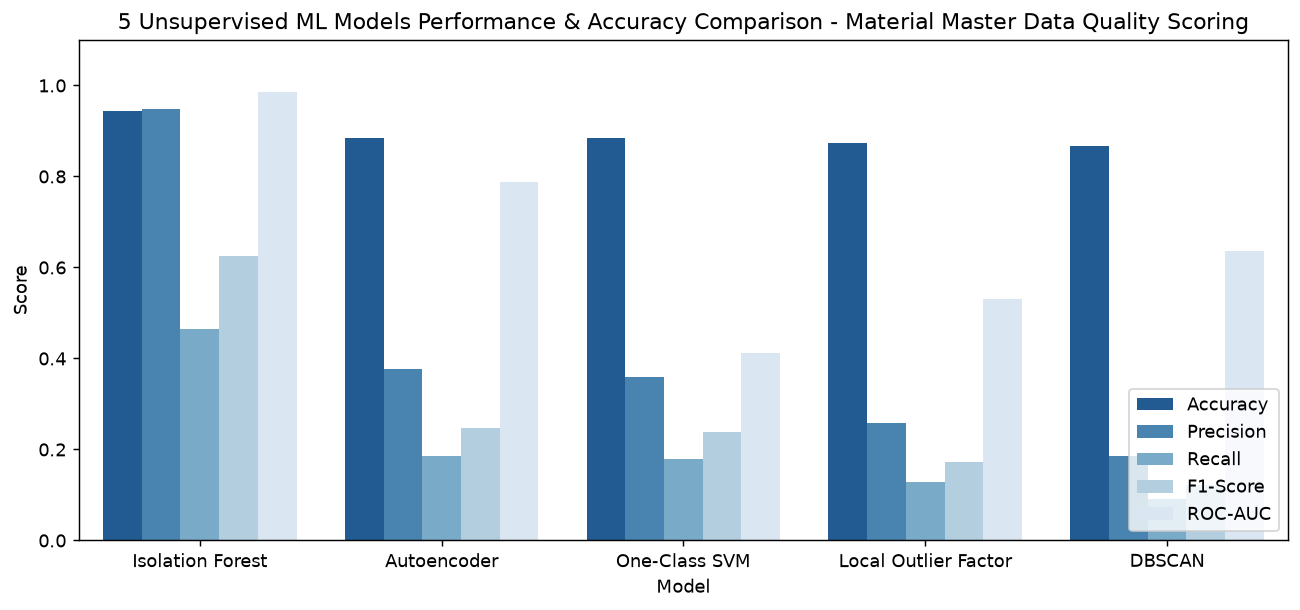

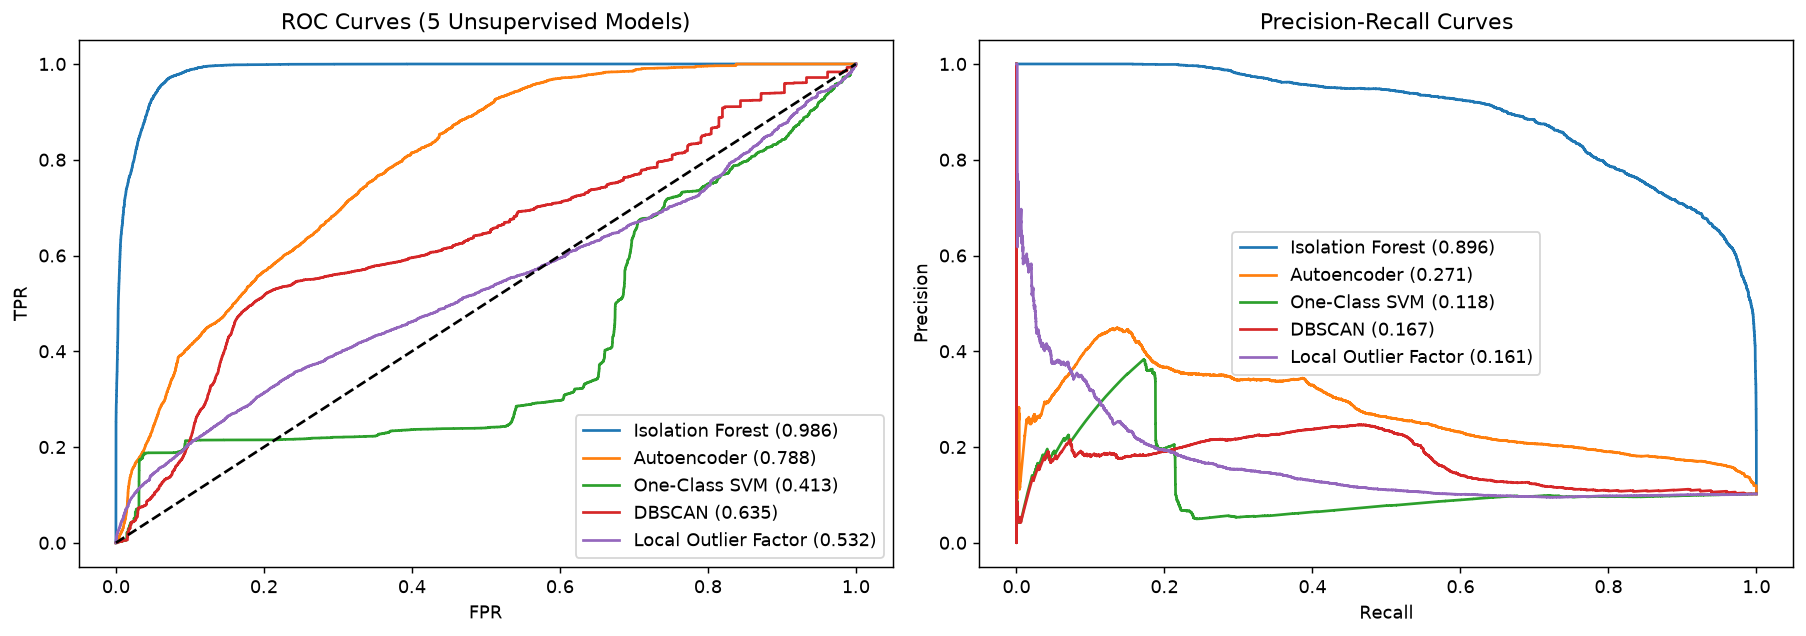

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised ML Models Performance & Accuracy Comparison - Material Master Data Quality Scoring')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                       Feature  Importance
              mdq_defect_index    0.450433
              mdq_health_score    0.293600
   missing_critical_fields_cnt    0.062665
               log_stock_value    0.040436
            log_valuated_stock    0.038121
        days_since_last_change    0.017382
            completeness_ratio    0.013644
     mara_views_maintained_cnt    0.012898
           log_effective_price    0.012246
          effective_unit_price    0.011877
              desc_token_count    0.008175
implied_vs_book_price_diff_pct    0.007302
         dup_description_count    0.007159
      is_duplicate_description    0.005531
     is_missing_prod_hierarchy    0.005444


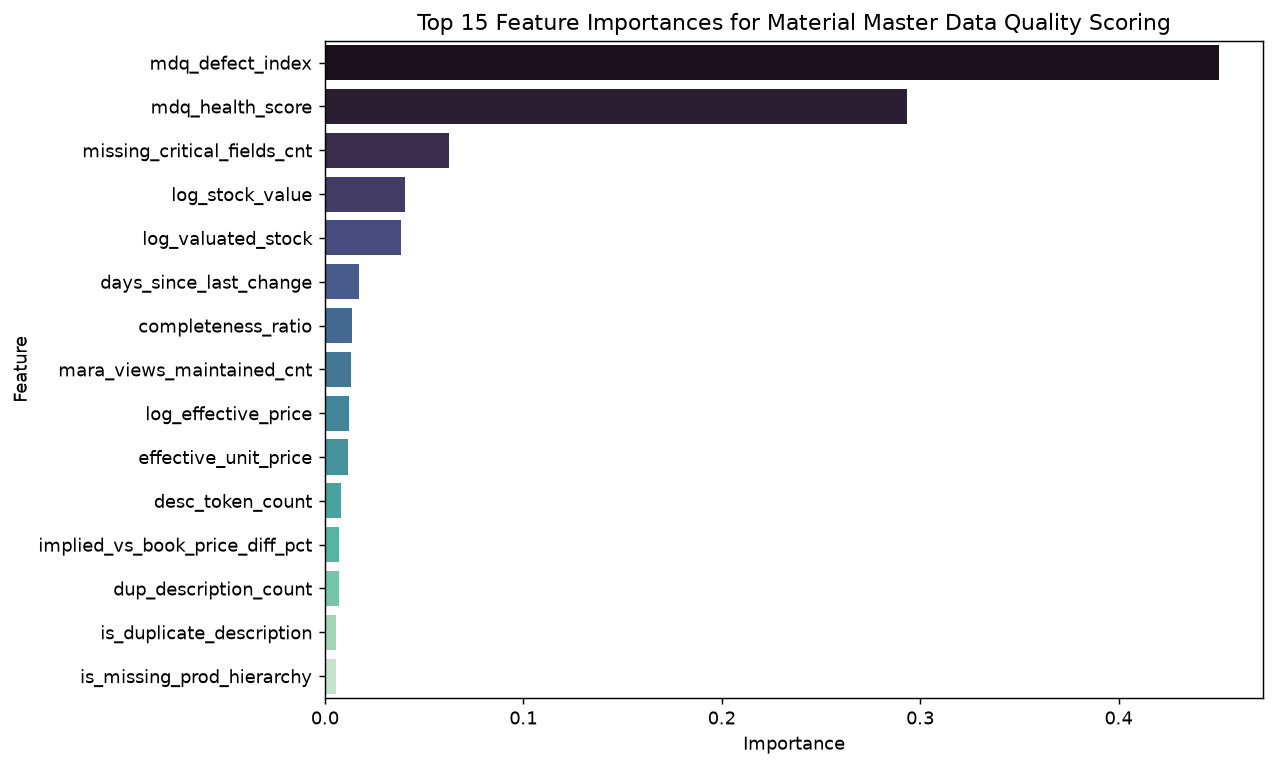

In [19]:
# 19. Feature Importance (All 32 Material Master Data Quality Features)
sub_feat_idx = np.random.choice(len(X_test_scaled), size=min(30000, len(X_test_scaled)), replace=False)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled[sub_feat_idx], scores_if[sub_feat_idx])

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Material Master Data Quality Scoring')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Prediction & Risk Triage using Selected #1 Champion Model
from src.models import SingleModelMaterialQualityDetector
from src.inference import score_with_single_model

detector = SingleModelMaterialQualityDetector(contamination=0.05, random_state=42, pretrained_model=iso_forest)
detector.fit(X_train_scaled)
df_scored = score_with_single_model(df, detector, scaler, FEATURE_COLS)

print(df_scored['risk_category'].value_counts())

audit_cols = ['source_schema', 'material_id', 'material_desc', 'material_type', 'plant', 'mdq_health_score', 'quality_issue_type', 'material_quality_anomaly_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: Isolation Forest for Material Master Data Quality Scoring...
[INFO] Champion Model fitted. Score range: [0.3500, 0.6663], Anomaly Threshold: 0.5537
risk_category
Low Risk         671826
Critical Risk     28604
High Risk          5686
Medium Risk        1103
Name: count, dtype: int64
source_schema material_id material_desc material_type plant  mdq_health_score                                quality_issue_type  material_quality_anomaly_prob risk_category
      HANA_P2      519535          HOSE          ZSPA                     0.0 Missing Valuation Class / Accounting View (BKLAS)                       0.966106 Critical Risk
      HANA_P2      519536          HOSE          ZSPA                     0.0 Missing Valuation Class / Accounting View (BKLAS)                       0.966106 Critical Risk
      HANA_P2      519541          HOSE          ZSPA                     0.0 Missing Valuation Class / Accounting View (BKLAS)                       0.96

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': iso_forest,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/material_quality_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion model bundle and scaler to models/")


Saved champion model bundle and scaler to models/
